In [ ]:
import os, sys, subprocess, zipfile, shutil
from google.colab import files
os.chdir('/content')

print(">>> Choose ece1512-projectA-mil.zip")
up = files.upload()
zname = [n for n in up if n.endswith('.zip')][0]
EXTRACT = '/content/repo_extract'
shutil.rmtree(EXTRACT, ignore_errors=True)
zipfile.ZipFile(zname).extractall(EXTRACT)

# The GitHub zip unpacks to a single folder (ece1512-projectA-mil-main); locate it instead of hard-coding the name.
REPO = [os.path.join(EXTRACT, n) for n in os.listdir(EXTRACT) if os.path.isdir(os.path.join(EXTRACT, n))][0]
print('REPO =', REPO)
PROJECT_DIR = f'{REPO}/starter'
subprocess.run(["pip", "install", "-q", "torchmetrics", "h5py", "pandas",
                "scikit-learn", "pyyaml", "tabulate", "huggingface_hub"], check=True)

from huggingface_hub import hf_hub_download
for key in ["C16", "C17", "BRACS"]:
    p = hf_hub_download("LeonYe/ECE1512-WSI-Feature",
                        f"feature/{key}/patch_feats_pretrain_medical_ssl.h5",
                        repo_type="dataset", local_dir="/content/datasets/hf")
    d = f"{PROJECT_DIR}/feature/{key}"
    os.makedirs(d, exist_ok=True)
    dst = f"{d}/patch_feats_pretrain_medical_ssl.h5"
    if os.path.lexists(dst):
        os.remove(dst)
    os.symlink(p, dst)
    print(key, "ready", f"{os.path.getsize(dst)/1e9:.2f} GB")

os.chdir(PROJECT_DIR)
sys.path[:0] = [PROJECT_DIR, f"{REPO}/src"]
os.makedirs("results", exist_ok=True)
print("Setup done. cwd =", os.getcwd())

>>> Choose ece1512-projectA-mil.zip


Saving ece1512-projectA-mil.zip to ece1512-projectA-mil.zip


feature/C16/patch_feats_pretrain_medical(…): reconstructing file:   0%|          |  0.00B / 7.22GB            

feature/C16/patch_feats_pretrain_medical(…): downloading bytes:           |  0.00B            

C16 ready 7.22 GB


...

feature/C17/patch_feats_pretrain_medical(…): downloading bytes:           |  0.00B            

C17 ready 4.08 GB


feature/BRACS/patch_feats_pretrain_medic(…): reconstructing file:   0%|          |  0.00B / 4.24GB            

feature/BRACS/patch_feats_pretrain_medic(…): downloading bytes:           |  0.00B            

BRACS ready 4.24 GB
Setup done. cwd = /content/ece1512-projectA-mil/starter


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, torch
from train_eval import run_experiment, device
from extension import run_extension, VARIANTS

print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (switch to GPU!)")

SEEDS = [42]                       # [42, 43, 44] for mean +/- std (3x longer)
KEYS = ["C16", "C17", "BRACS"]

BASE = {}
for k in KEYS:
    for s in SEEDS:
        BASE[(k, s)] = run_experiment(k, seed=s, verbose=False)
print("\nBaseline finished.")

Device: cuda | Tesla T4

### C16 | seed 42 | pooling=attention | splits 242/27/129
[C16] best val epoch=3 | TEST acc=88.37 auc=0.9342 f1=0.8668 loss=0.2804

### C17 | seed 42 | pooling=attention | splits 269/30/200
[C17] best val epoch=22 | TEST acc=78.50 auc=0.8391 f1=0.5323 loss=0.7047

### BRACS | seed 42 | pooling=attention | splits 389/62/86
[BRACS] best val epoch=6 | TEST acc=39.53 auc=0.8042 f1=0.3494 loss=1.4265

Baseline finished.


In [ ]:
EXT = {}
for k in KEYS:
    for s in SEEDS:
        EXT[(k, s, "full")] = run_extension(k, seed=s, tag="full", verbose=False, **VARIANTS["full"])
print("\nFull extension finished.")

[C16|full] best val epoch=3 | TEST acc=89.92 auc=0.9250 f1=0.8860 loss=0.3297
[C17|full] best val epoch=9 | TEST acc=78.00 auc=0.8212 f1=0.4841 loss=0.7527
[BRACS|full] best val epoch=4 | TEST acc=43.02 auc=0.8000 f1=0.3705 loss=1.4000

Full extension finished.


In [ ]:
for k in ["C17", "BRACS"]:
    for name in ["cb_only", "drop_only", "ent_only"]:
        EXT[(k, SEEDS[0], name)] = run_extension(k, seed=SEEDS[0], tag=name,
                                                  verbose=False, **VARIANTS[name])
print("\nAblations finished.")

[C17|cb_only] best val epoch=7 | TEST acc=80.00 auc=0.8232 f1=0.4689 loss=0.7075
[C17|drop_only] best val epoch=26 | TEST acc=77.50 auc=0.8250 f1=0.5636 loss=0.7804
[C17|ent_only] best val epoch=18 | TEST acc=75.00 auc=0.8154 f1=0.5004 loss=0.7478
[BRACS|cb_only] best val epoch=6 | TEST acc=39.53 auc=0.7807 f1=0.3494 loss=1.4347
[BRACS|drop_only] best val epoch=6 | TEST acc=39.53 auc=0.8026 f1=0.3374 loss=1.4170
[BRACS|ent_only] best val epoch=6 | TEST acc=39.53 auc=0.8044 f1=0.3494 loss=1.4449

Ablations finished.


=== Comparison ===


,Dataset,Seed,Method,Acc (%),AUC,F1,Loss,Best ep
2,BRACS,42,ABMIL baseline,39.5349,0.8042,0.3494,1.4265,6
9,BRACS,42,cb_only,39.5349,0.7807,0.3494,1.4347,6
10,BRACS,42,drop_only,39.5349,0.8026,0.3374,1.4170,6
11,BRACS,42,ent_only,39.5349,0.8044,0.3494,1.4449,6
5,BRACS,42,full,43.0233,0.8000,0.3705,1.4000,4
0,C16,42,ABMIL baseline,88.3721,0.9342,0.8668,0.2804,3
3,C16,42,full,89.9225,0.9250,0.8860,0.3297,3
1,C17,42,ABMIL baseline,78.5000,0.8391,0.5323,0.7047,22
6,C17,42,cb_only,80.0000,0.8232,0.4689,0.7075,7
7,C17,42,drop_only,77.5000,0.8250,0.5636,0.7804,26


=== Mean/std (std is NaN with 1 seed) ===


Acc (%)         AUC          F1        Loss    
                           mean std    mean std    mean std    mean std
Dataset Method                                                         
BRACS   ABMIL baseline  39.5349 NaN  0.8042 NaN  0.3494 NaN  1.4265 NaN
        cb_only         39.5349 NaN  0.7807 NaN  0.3494 NaN  1.4347 NaN
        drop_only       39.5349 NaN  0.8026 NaN  0.3374 NaN  1.4170 NaN
        ent_only        39.5349 NaN  0.8044 NaN  0.3494 NaN  1.4449 NaN
        full            43.0233 NaN  0.8000 NaN  0.3705 NaN  1.4000 NaN
C16     ABMIL baseline  88.3721 NaN  0.9342 NaN  0.8668 NaN  0.2804 NaN
        full            89.9225 NaN  0.9250 NaN  0.8860 NaN  0.3297 NaN
C17     ABMIL baseline  78.5000 NaN  0.8391 NaN  0.5323 NaN  0.7047 NaN
        cb_only         80.0000 NaN  0.8232 NaN  0.4689 NaN  0.7075 NaN
        drop_only       77.5000 NaN  0.8250 NaN  0.5636 NaN  0.7804 NaN
        ent_only        75.0000 NaN  0.8154 NaN  0.5004 NaN  0.7478 NaN
        full            78.0000 NaN  0.8212 NaN  0.4841 NaN  0.7527 NaN

=== Attention sparsity ===


,Dataset,Method,norm. entropy,top-1% mass
0,C16,baseline,0.8378,0.2627
1,C16,full,0.8133,0.2887
2,C17,baseline,0.7195,0.3845
3,C17,full,0.7541,0.3994
4,BRACS,baseline,0.7361,0.4554
5,BRACS,full,0.7144,0.4729


=== Per-class F1 ===


,Dataset,Method,per-class F1
0,C16,baseline,"[0.914, 0.819]"
1,C16,full,"[0.925, 0.847]"
2,C17,baseline,"[0.922, 0.24, 0.188, 0.78]"
3,C17,full,"[0.902, 0.095, 0.154, 0.785]"
4,BRACS,baseline,"[0.222, 0.333, 0.125, 0.308, 0.235, 0.412, 0.811]"
5,BRACS,full,"[0.364, 0.286, 0.2, 0.118, 0.316, 0.5, 0.811]"


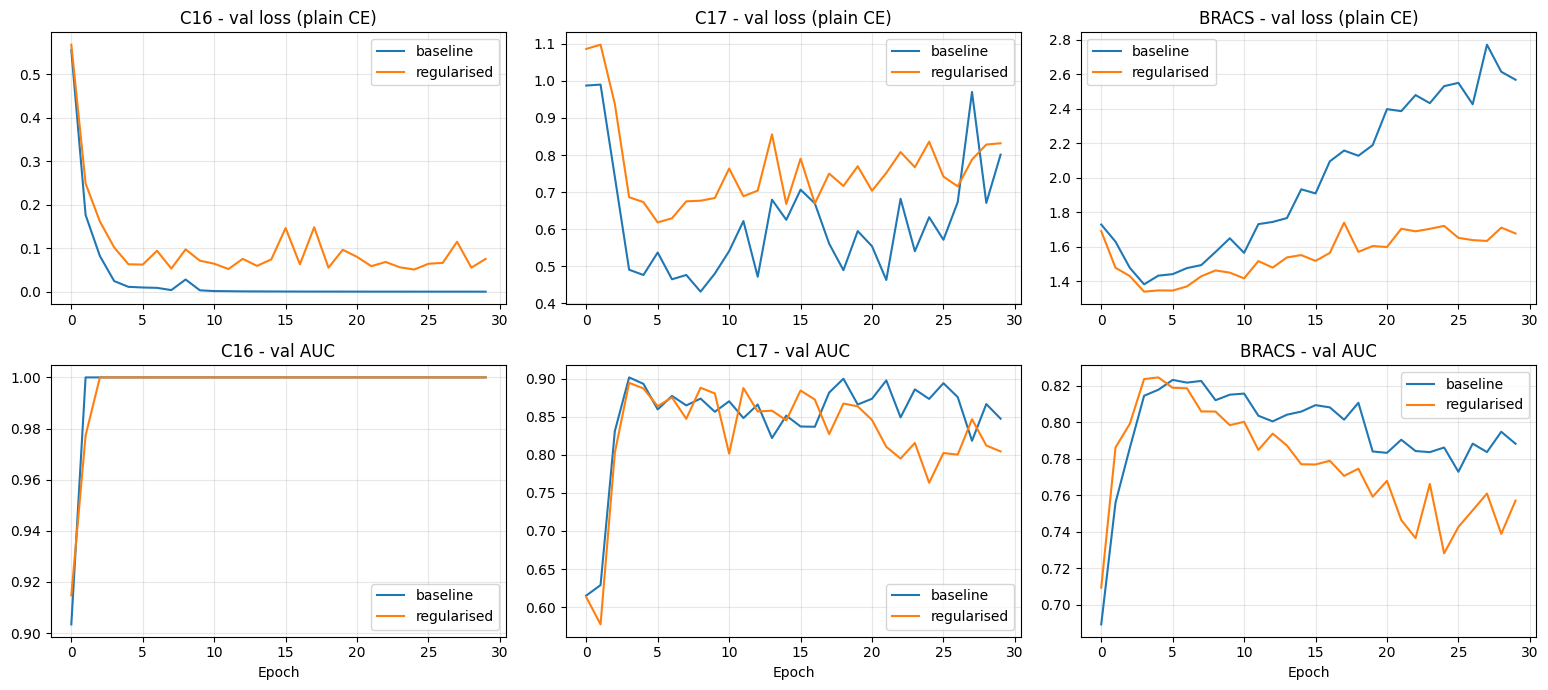

In [ ]:
from sklearn.metrics import f1_score

rows = []
for (k, s), r in BASE.items():
    rows.append({"Dataset": k, "Seed": s, "Method": "ABMIL baseline", "Acc (%)": r["test"]["acc"],
                 "AUC": r["test"]["auc"], "F1": r["test"]["f1"], "Loss": r["test"]["loss"], "Best ep": r["best_epoch"]})
for (k, s, name), r in EXT.items():
    rows.append({"Dataset": k, "Seed": s, "Method": name, "Acc (%)": r["test"]["acc"],
                 "AUC": r["test"]["auc"], "F1": r["test"]["f1"], "Loss": r["test"]["loss"], "Best ep": r["best_epoch"]})
cmp_df = pd.DataFrame(rows).sort_values(["Dataset", "Method"])
cmp_df.to_csv("results/extension_comparison.csv", index=False)
print("=== Comparison ==="); display(cmp_df.round(4))

agg = cmp_df.groupby(["Dataset", "Method"])[["Acc (%)", "AUC", "F1", "Loss"]].agg(["mean", "std", "count"]).round(4)
# flat CSV: one row per (dataset, method); std is written as NA when only one seed was run
flat = pd.DataFrame({"Dataset": [i[0] for i in agg.index], "Method": [i[1] for i in agg.index],
                     "n_seeds": agg[("Acc (%)", "count")].astype(int).values})
for m, name in [("Acc (%)", "Acc"), ("AUC", "AUC"), ("F1", "F1"), ("Loss", "Loss")]:
    flat[f"{name}_mean"] = agg[(m, "mean")].values
    flat[f"{name}_std"] = ["NA" if n < 2 else v for n, v in zip(flat.n_seeds, agg[(m, "std")].values)]
flat.to_csv("results/extension_comparison_meanstd.csv", index=False)
print("=== Mean/std (std is NA with 1 seed) ==="); display(flat)

att_rows = []
for k in KEYS:
    for label, d in [("baseline", BASE[(k, SEEDS[0])]["att_df"]), ("full", EXT[(k, SEEDS[0], "full")]["att_df"])]:
        att_rows.append({"Dataset": k, "Method": label,
                         "norm. entropy": d.norm_entropy.mean(), "top-1% mass": d.top1pct_mass.mean()})
att_cmp = pd.DataFrame(att_rows)
att_cmp.to_csv("results/extension_attention.csv", index=False)
print("=== Attention sparsity ==="); display(att_cmp.round(4))

pc_rows = []
for k in KEYS:
    for label, r in [("baseline", BASE[(k, SEEDS[0])]), ("full", EXT[(k, SEEDS[0], "full")])]:
        y = r["test_labels"].numpy(); p = r["test_probs"].argmax(1).numpy()
        f = f1_score(y, p, labels=list(range(int(r["test_probs"].shape[1]))), average=None, zero_division=0)
        pc_rows.append({"Dataset": k, "Method": label, "per-class F1": np.round(f, 3).tolist()})
pc_df = pd.DataFrame(pc_rows)
pc_df.to_csv("results/extension_per_class_f1.csv", index=False)
print("=== Per-class F1 ==="); display(pc_df)

fig, ax = plt.subplots(2, len(KEYS), figsize=(5.2 * len(KEYS), 7), squeeze=False)
for j, k in enumerate(KEYS):
    hb, he = BASE[(k, SEEDS[0])]["history"], EXT[(k, SEEDS[0], "full")]["history"]
    ax[0, j].plot(hb.val_loss, label="baseline"); ax[0, j].plot(he.val_loss, label="regularised")
    ax[0, j].set_title(f"{k} - val loss (plain CE)"); ax[0, j].legend(); ax[0, j].grid(alpha=.3)
    ax[1, j].plot(hb.val_auc, label="baseline"); ax[1, j].plot(he.val_auc, label="regularised")
    ax[1, j].set_title(f"{k} - val AUC"); ax[1, j].set_xlabel("Epoch"); ax[1, j].legend(); ax[1, j].grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/extension_curves.png", dpi=200); plt.show()

In [2]:
# %% CELL 6 - download results (fixed: explicit imports and absolute paths)
import os, shutil
from google.colab import files

RESULTS_DIR = f"{REPO}/starter/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

archive = shutil.make_archive("/content/extension_results", "zip", RESULTS_DIR)
print("Created:", archive)
files.download(archive)

Created: /content/extension_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# Sanity check: PyTorch weighted CE with label smoothing equals report Eq. (6) (hand-computed) for one example.
import torch, torch.nn as nn
w = torch.tensor([0.211, 1.912, 0.939, 0.939])
x = torch.randn(1, 4); y = torch.tensor([1])
print(nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)(x, y).item())
lp = torch.log_softmax(x, 1)[0]
print((0.9*(-lp[1]) + 0.1/(4*w[1])*(-(w*lp).sum())).item())

1.7932857275009155
1.793285608291626
